# Génération d’images et évaluation

**Objectif :** apprendre un générateur de chiffres puis distinguer ressemblance de distribution, diversité et cohérence des images.

Le modèle génératif est un mélange de gaussiennes par classe, appris dans un espace PCA. Il produit de nouvelles images 8 × 8. Les GAN, VAE et modèles de diffusion sont d’autres familles de générateurs.

Le FID et l’Inception Score standard utilisent Inception préentraîné. Nous calculons ici une **distance de Fréchet dans les caractéristiques PCA**, explicitement nommée **Fréchet-PCA**, pour montrer le principe sans télécharger de réseau. Ce nombre n’est pas comparable à un FID Inception publié.

In [20]:
# Cloner le dépôt GitHub
!git clone https://github.com/Et-taky/metric_evaluation_IA_avancee.git

Cloning into 'metric_evaluation_IA_avancee'...
remote: Enumerating objects: 57, done.
remote: Counting objects: 100% (57/57), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 57 (delta 4), reused 56 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (57/57), 3.71 MiB | 7.09 MiB/s, done.
Resolving deltas: 100% (4/4), done.


In [21]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
import pandas as pd

# Définir la racine du projet cloné
ROOT = Path("/content/metric_evaluation_IA_avancee")

# Vérifier la structure
assert (ROOT / "src").exists(), "Le dossier src est introuvable"

# Ajouter le projet au Python path
sys.path.insert(0, str(ROOT))

# Créer le dossier results s'il n'existe pas
(ROOT / "results").mkdir(exist_ok=True)

print("Projet chargé avec succès :", ROOT)
print("Dossiers disponibles :", [p.name for p in ROOT.iterdir()])
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


Projet chargé avec succès : /content/metric_evaluation_IA_avancee
Dossiers disponibles : ['presentations', 'notebooks', 'src', 'metric_evaluation_IA_avancee', '.gitignore', 'requirements.txt', 'data', 'results', '.git', 'README.md']


## 1. Séparer les images réelles
Le générateur et l’extracteur PCA apprennent sur l’entraînement. Les 450 images de test restent la référence réelle indépendante. La normalisation divise les pixels par 16, leur valeur maximale dans digits.

In [22]:
X,y=load_digits(return_X_y=True)
X=X/16.0
X_train,X_real,y_train,y_real=train_test_split(X,y,test_size=.25,stratify=y,random_state=42)
pca=PCA(n_components=20,random_state=42).fit(X_train)
Z_train=pca.transform(X_train)
print("Entraînement :",len(X_train),"; référence réelle :",len(X_real))
print("Variance conservée par la PCA :",round(pca.explained_variance_ratio_.sum(),3))


Entraînement : 1347 ; référence réelle : 450
Variance conservée par la PCA : 0.895


## 2. Apprendre et générer de nouvelles images
Pour chaque chiffre, un mélange de deux gaussiennes apprend des régions probables dans l’espace de 20 caractéristiques. On tire 45 nouveaux points par classe, puis la PCA inverse les transforme en pixels. Le résultat peut être flou ou incohérent : l’évaluation sert à l’observer.

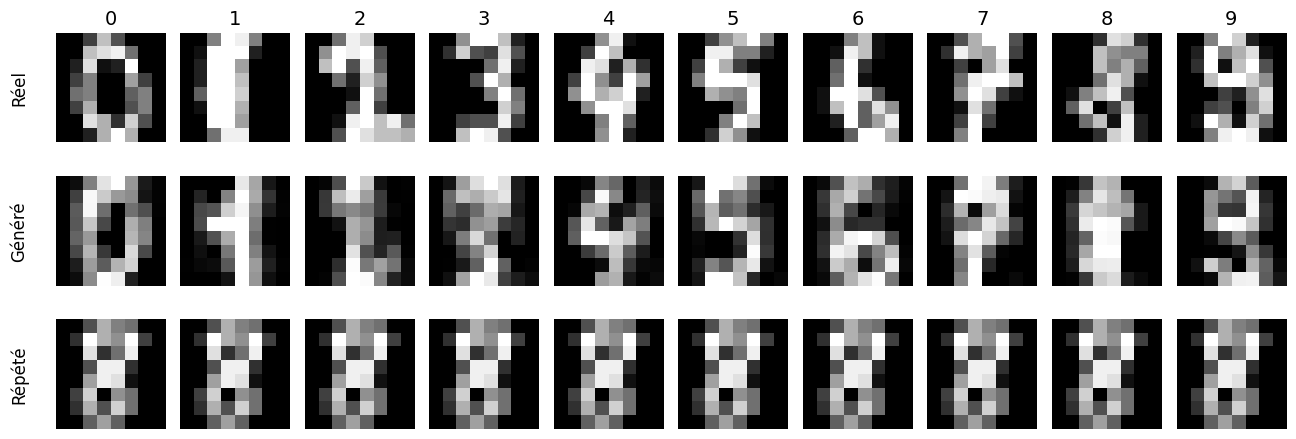

450 images générées, avec 45 demandes de chaque chiffre.


In [23]:
generated=[];requested=[]
for digit in range(10):
    generator=GaussianMixture(n_components=2,covariance_type="full",reg_covar=.02,random_state=42+digit)
    generator.fit(Z_train[y_train==digit])
    latent,_=generator.sample(45)
    generated.append(np.clip(pca.inverse_transform(latent),0,1))
    requested.extend([digit]*45)
X_gen=np.vstack(generated);requested=np.array(requested)
# Contre-exemple volontaire : répéter une seule vraie image 450 fois.
one=X_train[y_train==8][0]
X_repeat=np.repeat(one[None,:],len(X_gen),axis=0)
np.savez(ROOT/"data/generation_chiffres.npz",real=X_real,generated=X_gen,repeated=X_repeat,requested=requested)
fig,axes=plt.subplots(3,10,figsize=(13,4.8))
for col in range(10):
    real=X_real[y_real==col][0]
    for row,image in enumerate([real,X_gen[col*45],X_repeat[col]]):
        axes[row,col].imshow(image.reshape(8,8),cmap="gray",vmin=0,vmax=1)
        axes[row,col].axis("off")
    axes[0,col].set_title(str(col),fontsize=14)
for ax,label in zip(axes[:,0],["Réel","Généré","Répété"]):
    ax.text(-.25,.5,label,transform=ax.transAxes,ha="right",va="center",rotation=90,fontsize=12)
plt.tight_layout();plt.savefig(ROOT/"results/generation_exemples.png",dpi=180,bbox_inches="tight");plt.show()
print("450 images générées, avec 45 demandes de chaque chiffre.")


## 3. Comprendre le FID par la distance de Fréchet
Le FID résume les moyennes et covariances des caractéristiques Inception des ensembles réels et générés. Une petite valeur indique des statistiques proches dans cet espace.

Formule : distance = carré de la différence des moyennes + terme de différence des covariances.

**Ici**, l’espace de caractéristiques est celui de la PCA apprise sur les chiffres. La formule de Fréchet est la même, mais l’extracteur diffère : le résultat est **Fréchet-PCA**, pas un FID standard. Les covariances utilisent `ddof=1`. Le calcul PSD symétrique évite les petites parties imaginaires que peut produire une racine matricielle générale.

In [24]:
def frechet_features(a,b):
    mu_a,mu_b=a.mean(axis=0),b.mean(axis=0)
    cov_a,cov_b=np.cov(a,rowvar=False),np.cov(b,rowvar=False)
    eigenvalues,vectors=np.linalg.eigh(cov_a)
    sqrt_a=(vectors*np.sqrt(np.clip(eigenvalues,0,None)))@vectors.T
    product=sqrt_a@cov_b@sqrt_a
    product=(product+product.T)/2
    trace_root=np.sqrt(np.clip(np.linalg.eigvalsh(product),0,None)).sum()
    value=np.sum((mu_a-mu_b)**2)+np.trace(cov_a)+np.trace(cov_b)-2*trace_root
    return float(max(0,value))
Z_real=pca.transform(X_real)
frechet_gen=frechet_features(Z_real,pca.transform(X_gen))
frechet_repeat=frechet_features(Z_real,pca.transform(X_repeat))
assert frechet_features(Z_real,Z_real)<1e-8
print("Fréchet-PCA, générateur :",round(frechet_gen,4))
print("Fréchet-PCA, répétition :",round(frechet_repeat,4))


Fréchet-PCA, générateur : 0.1283
Fréchet-PCA, répétition : 6.512


## 4. Mesurer la diversité et une cohérence indicative
Un classifieur de chiffres indépendant du générateur apprend sur l’entraînement. Il indique combien de classes il reconnaît dans les sorties et si la classe reconnue correspond au chiffre demandé. Son accord est un **indicateur imparfait**, pas une preuve de qualité visuelle.

L’Inception Score standard combine des prédictions individuelles nettes et une distribution globale de classes variée, avec Inception. Nous ne le remplaçons pas par le score de notre classifieur : les indicateurs ci-dessous portent leur propre nom.

On contrôle aussi les doublons exacts, après arrondi à six décimales. L’absence de doublons n’exclut pas la mémorisation ni le manque de diversité perceptuelle.

Accuracy du classifieur sur les vraies images de test : 0.9778
               Fréchet-PCA  Classes reconnues  Doublons  Accord avec demande
Ensemble                                                                    
Générateur          0.1283                 10    0.0000                 0.98
Image répétée       6.5120                  1    0.9978                 0.10


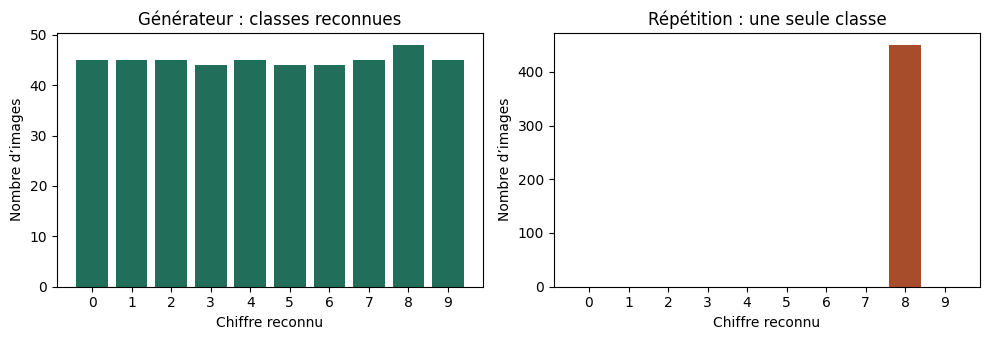

In [25]:
evaluator=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=42)).fit(X_train,y_train)
print("Accuracy du classifieur sur les vraies images de test :",round(evaluator.score(X_real,y_real),4))
pred_gen=evaluator.predict(X_gen);pred_repeat=evaluator.predict(X_repeat)
def diversity(images,pred):
    unique=len(np.unique(np.round(images,6),axis=0))
    return len(np.unique(pred)),1-unique/len(images)
classes_gen,duplicates_gen=diversity(X_gen,pred_gen)
classes_repeat,duplicates_repeat=diversity(X_repeat,pred_repeat)
summary=pd.DataFrame([
 {"Ensemble":"Générateur","Fréchet-PCA":frechet_gen,"Classes reconnues":classes_gen,"Doublons":duplicates_gen,"Accord avec demande":float(np.mean(pred_gen==requested))},
 {"Ensemble":"Image répétée","Fréchet-PCA":frechet_repeat,"Classes reconnues":classes_repeat,"Doublons":duplicates_repeat,"Accord avec demande":float(np.mean(pred_repeat==requested))}]).set_index("Ensemble")
print(summary.round(4).to_string())
summary.to_csv(ROOT/"results/generation_scores.csv")
(ROOT/"results/generation_scores.json").write_text(summary.to_json(orient="index",indent=2,force_ascii=False))
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].hist(pred_gen,bins=np.arange(11)-.5,rwidth=.8,color="#216F5B")
axes[1].hist(pred_repeat,bins=np.arange(11)-.5,rwidth=.8,color="#A74D2C")
for ax,title in zip(axes,["Générateur : classes reconnues","Répétition : une seule classe"]):
    ax.set_xticks(range(10));ax.set_title(title);ax.set_xlabel("Chiffre reconnu");ax.set_ylabel("Nombre d’images")
plt.tight_layout();plt.savefig(ROOT/"results/generation_diversite.png",dpi=170);plt.show()
assert len(X_gen)==len(X_real)==len(X_repeat)==450
assert classes_repeat==1 and duplicates_repeat>.99


## 5. Interpréter les métriques sans les confondre
- **FID standard** : caractéristiques Inception, plus faible = distributions plus proches ; dépend du protocole, de l’extracteur et du nombre d’images. Non calculé ici.
- **Fréchet-PCA** : même principe statistique dans un petit espace adapté aux chiffres, calculé ici. Ne pas l’appeler « FID » dans le compte rendu.
- **Inception Score** : plus élevé est généralement souhaitable, combine confiance et diversité des classes, mais ne compare pas directement aux vraies images. Non calculé ici.
- **Diversité** : plusieurs classes et plusieurs variantes dans chaque classe ; compléter les indicateurs par l’observation.
- **Génération conditionnée par un texte** : CLIPScore peut mesurer un accord image-texte, mais il faut aussi inspecter le respect des objets et des relations. Non calculé ici.

Une seule belle image répétée peut sembler réaliste et pourtant manquer totalement de diversité. Les images générées par le mélange de gaussiennes sont un exercice sur digits, pas un système photoréaliste. Une vraie étude exige beaucoup plus de références et de sorties indépendantes, des réglages fixés et un examen de la mémorisation.

## Sources
- Heusel et al., FID, 2017 : https://arxiv.org/abs/1706.08500
- Salimans et al., Inception Score, 2016 : https://arxiv.org/abs/1606.03498
- GaussianMixture : https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html
- PCA : https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
